# Análise exploratória das instâncias de Solomon

Este notebook examina apenas os dados de entrada das 56 instâncias de Solomon (Solomon, 1987), sem resultados de solver nem rotas de referência, para identificar o que torna cada família difícil. A análise investiga como os clientes se distribuem no plano (agrupados, aleatórios ou mistos), qual a amplitude das janelas de tempo em relação ao horizonte, se a frota mínima decorre da capacidade ou das janelas e qual fração de pares de clientes admite encadeamento direto em uma mesma rota. A única exceção ao uso exclusivo de entradas é a contagem de veículos de referência do SINTEF, empregada somente na seção sobre limites de frota.

## 1. Preparação do ambiente

Nesta seção carregam-se as 56 instâncias e a tabela de veículos do SINTEF (restrita à seção 4). A tabela resume os parâmetros gerais lidos por família.

In [1]:
LANG = "pt"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import eda, io, paths, viz_eda
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
instances = io.read_archive(P["sintef_zip"])
sintef = io.read_references(P["sintef_bks"])

display(eda.localize_columns(eda.family_summary(instances), LANG))

,Família,Nº de instâncias,Nº de clientes,Limite de frota (K),Capacidade (Q),Horizonte,Tempo de serviço,Demanda total média
0,C1,9,100,25,200,1236,90.0,1810.0
1,C2,8,100,25,700,3390,90.0,1810.0
2,R1,12,100,25,200,230,10.0,1458.0
3,R2,11,100,25,1000,1000,10.0,1458.0
4,RC1,8,100,25,200,240,10.0,1724.0
5,RC2,8,100,25,1000,960,10.0,1724.0


### Insight

As 56 instâncias dividem-se em seis famílias com capacidades entre 200 e 1000, horizontes de 230 a 3390 e tempos de serviço de 90 (famílias C) ou 10 (R e RC). Como o horizonte e o tempo de serviço variam em ordens de grandeza entre famílias, as seções seguintes adotam métricas normalizadas pelo horizonte sempre que possível. O primeiro passo examina a distribuição espacial dos clientes.

## 2. Geografia dos clientes

Para observar o arranjo espacial dos clientes e a variação das janelas no plano, os painéis a seguir exibem mapas para seis instâncias representativas (C101, C201, R101, R201, RC101 e RC201). Cada ponto representa um cliente colorido pelo início de sua janela dividido pelo horizonte da própria instância, mantendo uma escala comum de 0 a 1 para a barra de cores compartilhada, enquanto o quadrado vermelho marca o depósito.

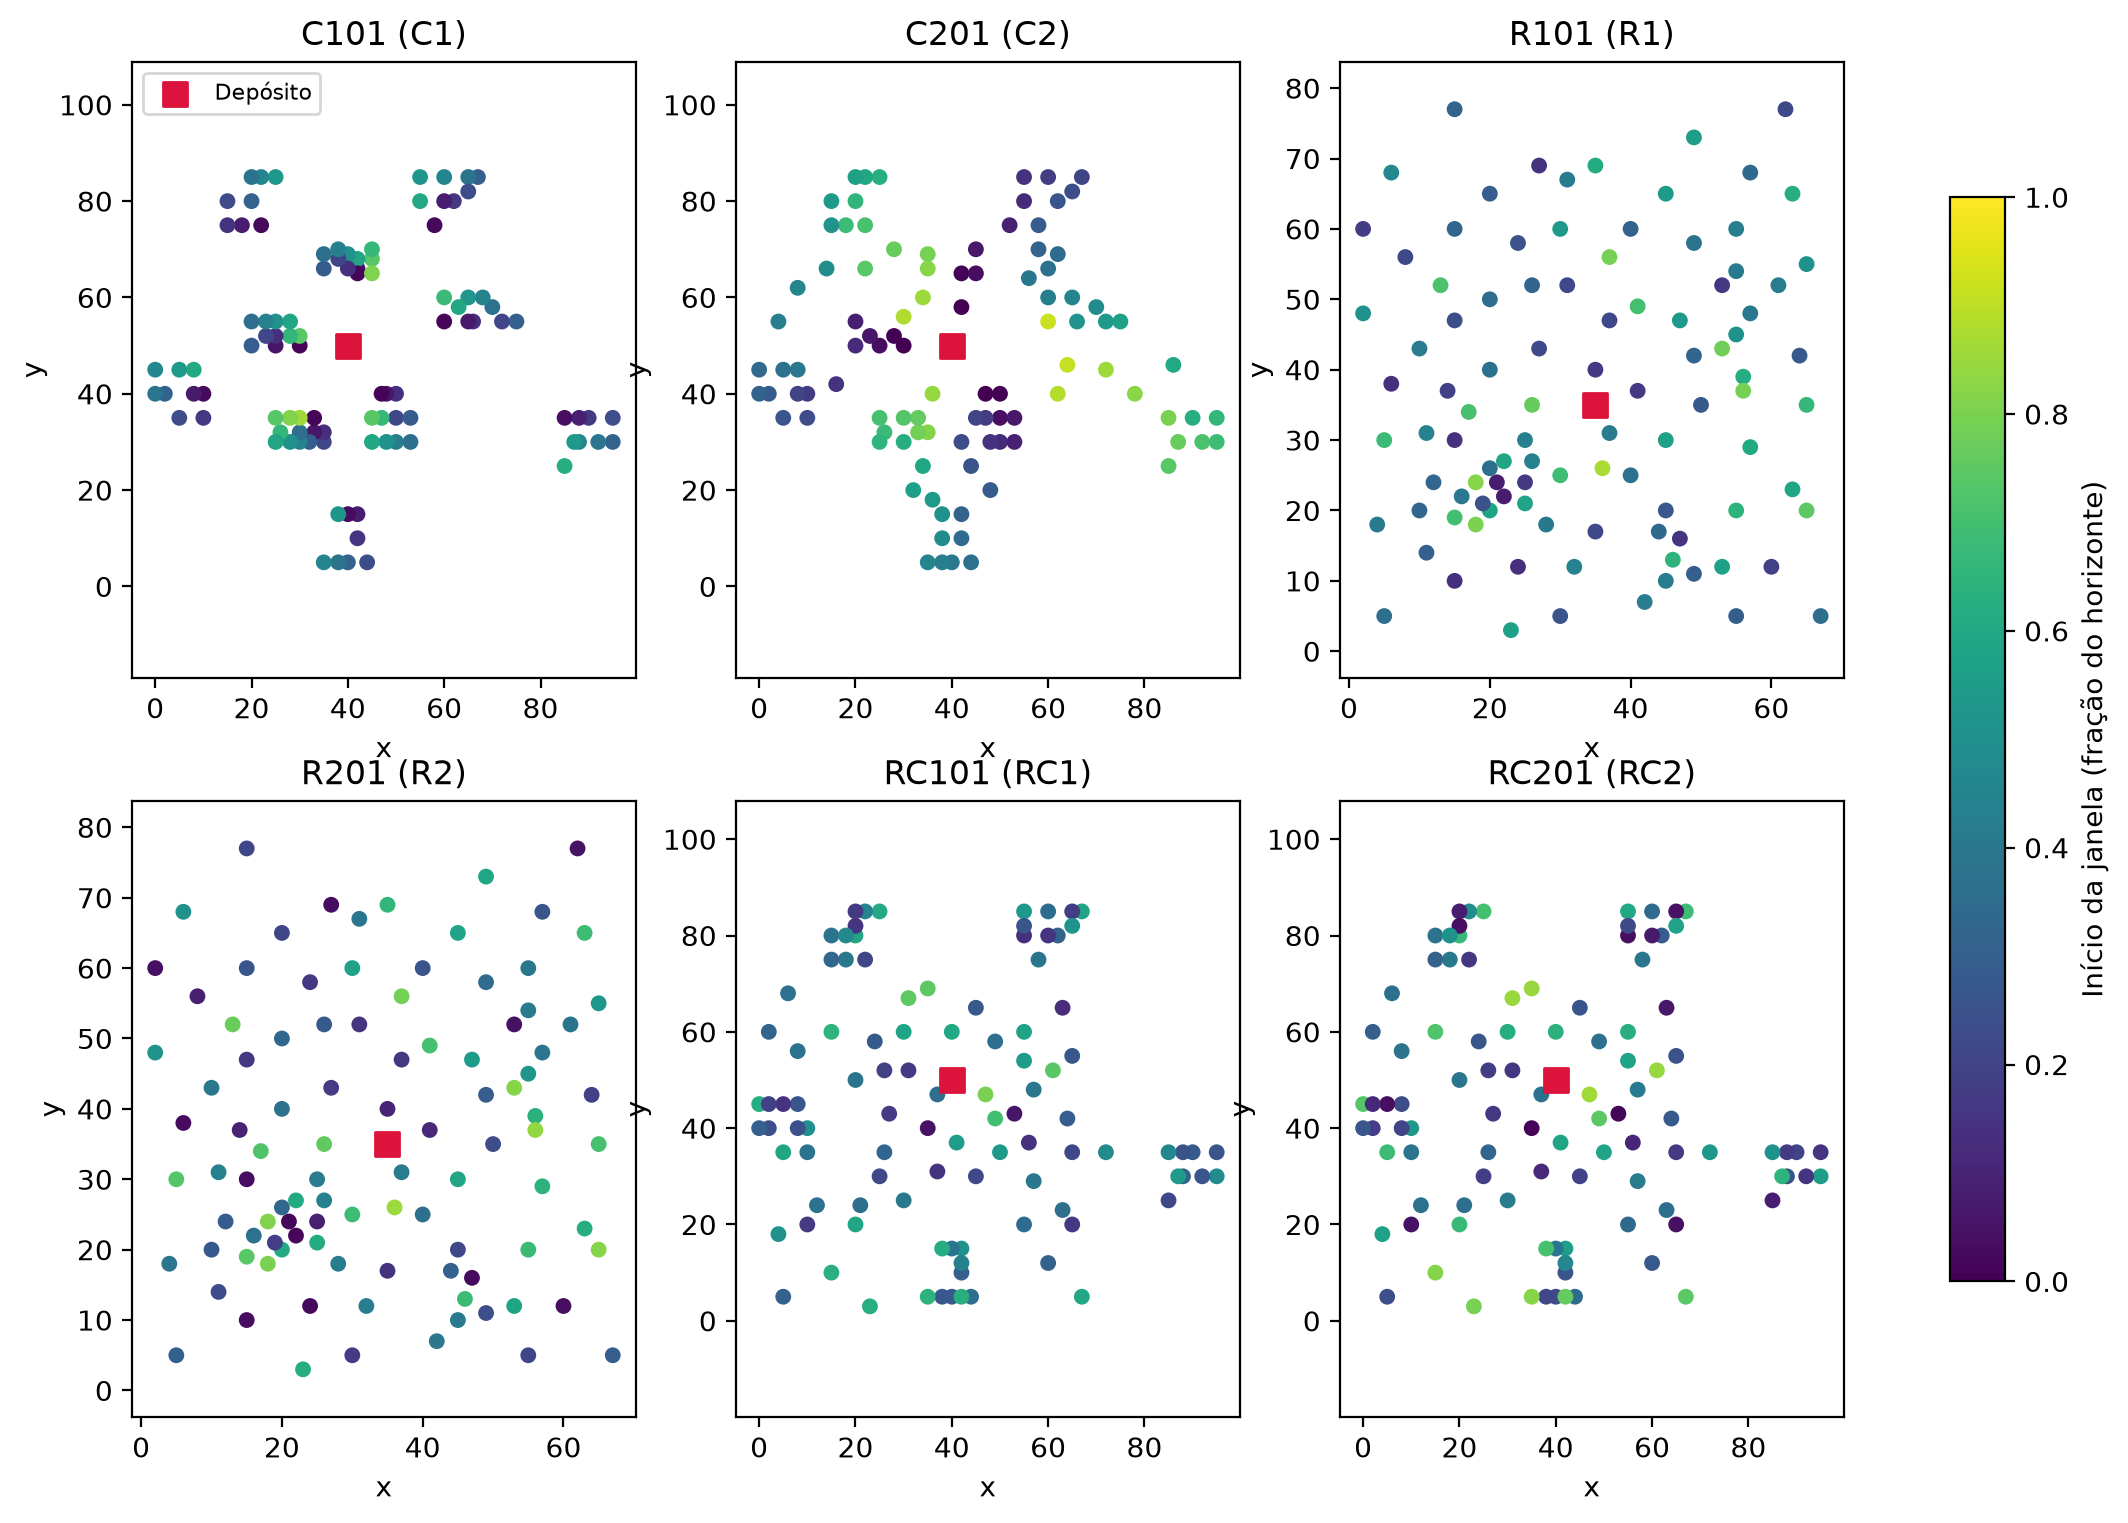

In [2]:
viz_eda.plot_family_layouts(instances, ["C101", "C201", "R101", "R201", "RC101", "RC201"], LANG)
plt.show()

### Insight

Em C101 e C201 os clientes formam agrupamentos compactos ao redor do depósito; em R101 e R201 espalham-se de modo aproximadamente uniforme; e em RC101 e RC201 combinam-se núcleos agrupados e pontos dispersos. Na escala normalizada de 0 a 1, as instâncias da série 2 (C201, R201 e RC201) exibem maior proporção de pontos em tons verde-azulados (janelas com abertura em fração mais tardia do horizonte) do que as da série 1 (C101, R101 e RC101), nas quais predominam tons violeta e azul. Nos agrupamentos das famílias C, clientes vizinhos tendem a compartilhar cores próximas de abertura de janela, ao passo que em R as cores distribuem-se sem padrão espacial visível; vale observar que R101 e R201 (bem como RC101 e RC201) partilham exatamente as mesmas coordenadas, variando apenas a cor conforme os horários.

Esta leitura é qualitativa e restringe-se a 6 das 56 instâncias, avaliando o início das janelas (enquanto a largura é medida na seção 3). Em versões anteriores do notebook, cada painel usava como teto o próprio horizonte, fazendo com que a barra de cores global refletisse apenas a última instância; esse defeito de escala foi corrigido em 2026-11-18 com a normalização para `[0, 1]`. Na sequência, quantifica-se a largura das janelas.

## 3. Janelas de tempo

Para medir o grau de restrição temporal, calculam-se por instância (apenas sobre clientes) a largura média da janela (`fim - início`), a largura média dividida pelo horizonte, a fração de clientes cuja janela cobre ao menos 90% do horizonte e o tempo de serviço médio dividido pelo horizonte. A tabela sintetiza as médias por família, enquanto o diagrama de caixa exibe a distribuição da largura relativa entre as instâncias de cada grupo.

,Família,Largura média da janela,Largura mediana da janela,Largura / horizonte,Clientes quase sem janela,Serviço / horizonte,Largura / horizonte (mín.),Largura / horizonte (máx.)
0,C1,320.991,318.444,0.260,0.104,0.073,0.049,0.690
1,C2,920.512,914.062,0.272,0.188,0.027,0.047,0.735
2,R1,86.959,82.833,0.378,0.027,0.043,0.043,0.667
3,R2,453.735,446.955,0.454,0.274,0.010,0.116,0.783
4,RC1,85.429,80.750,0.356,0.014,0.042,0.125,0.644
5,RC2,369.756,354.750,0.385,0.188,0.010,0.125,0.747


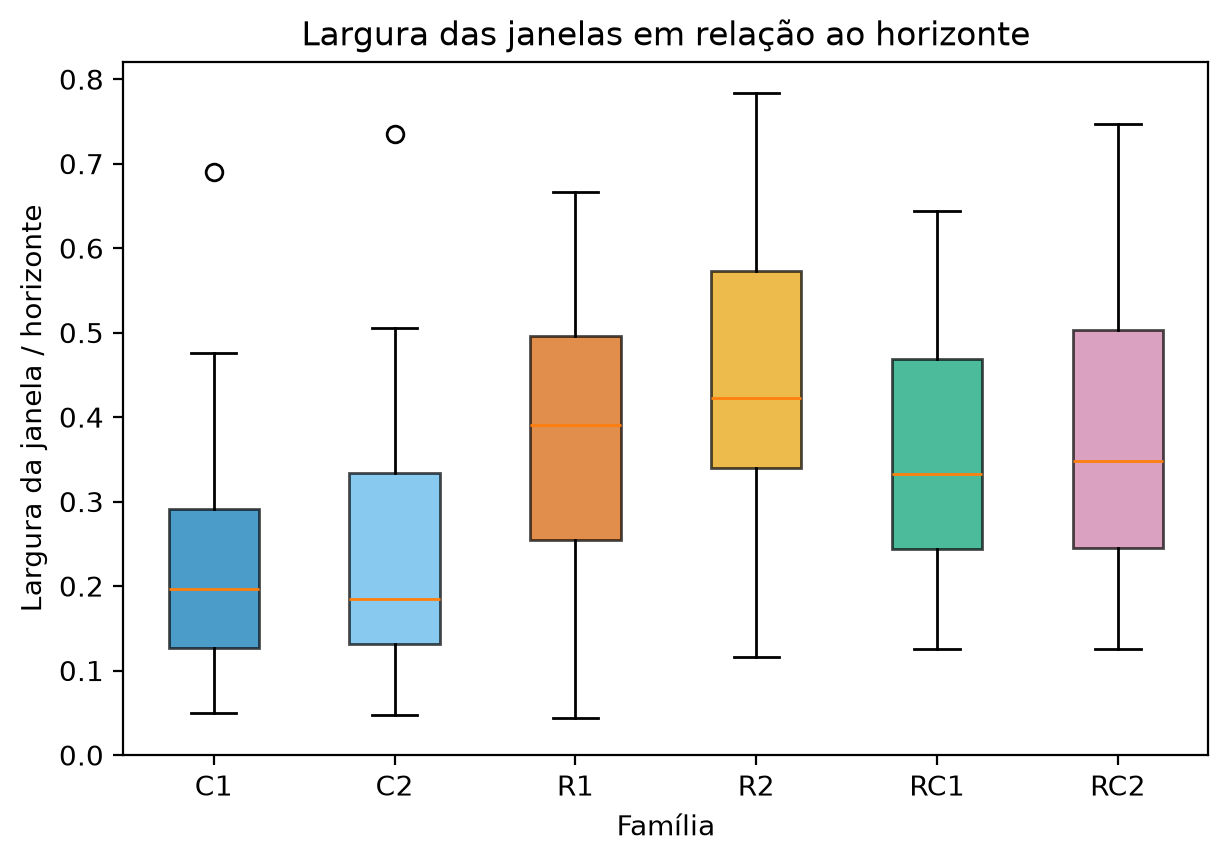

In [3]:
window = eda.window_stats(instances)
display(eda.localize_columns(eda.window_summary(window), LANG))

viz_eda.plot_window_widths(window, LANG)
plt.show()

### Insight

Em termos absolutos, as janelas médias da série 2 são muito mais extensas (C2: 920,5 contra 321,0 em C1; R2: 453,7 contra 87,0 em R1; RC2: 369,8 contra 85,4 em RC1). Quando divididas pelo horizonte, porém, as médias aproximam-se (C1: 0,260; C2: 0,272; R1: 0,378; R2: 0,454; RC1: 0,356; RC2: 0,385). O traço distintivo entre as séries está na proporção de clientes quase livres de restrição horária (janela igual ou superior a 90% do horizonte): 2,7% em R1 e 1,4% em RC1 contra 27,4% em R2 e 18,8% em RC2 (com 10,4% em C1 e 18,8% em C2). O tempo de serviço também consome maior fração do horizonte nas séries 1 (4,2% a 7,3%) do que nas séries 2 (1,0% a 2,7%). A dispersão interna é ampla, a largura relativa vai de 0,043 a 0,667 em R1 e de 0,116 a 0,783 em R2, de modo que a média familiar resume apenas parcialmente cada caso e não expõe a sobreposição temporal entre janelas, comparada a seguir entre duas instâncias.

A figura abaixo contrapõe a estrutura temporal de R101 (série 1) e R201 (série 2), desenhando uma barra horizontal por cliente do início ao fim de sua janela, ordenada pela abertura ao longo do horizonte.

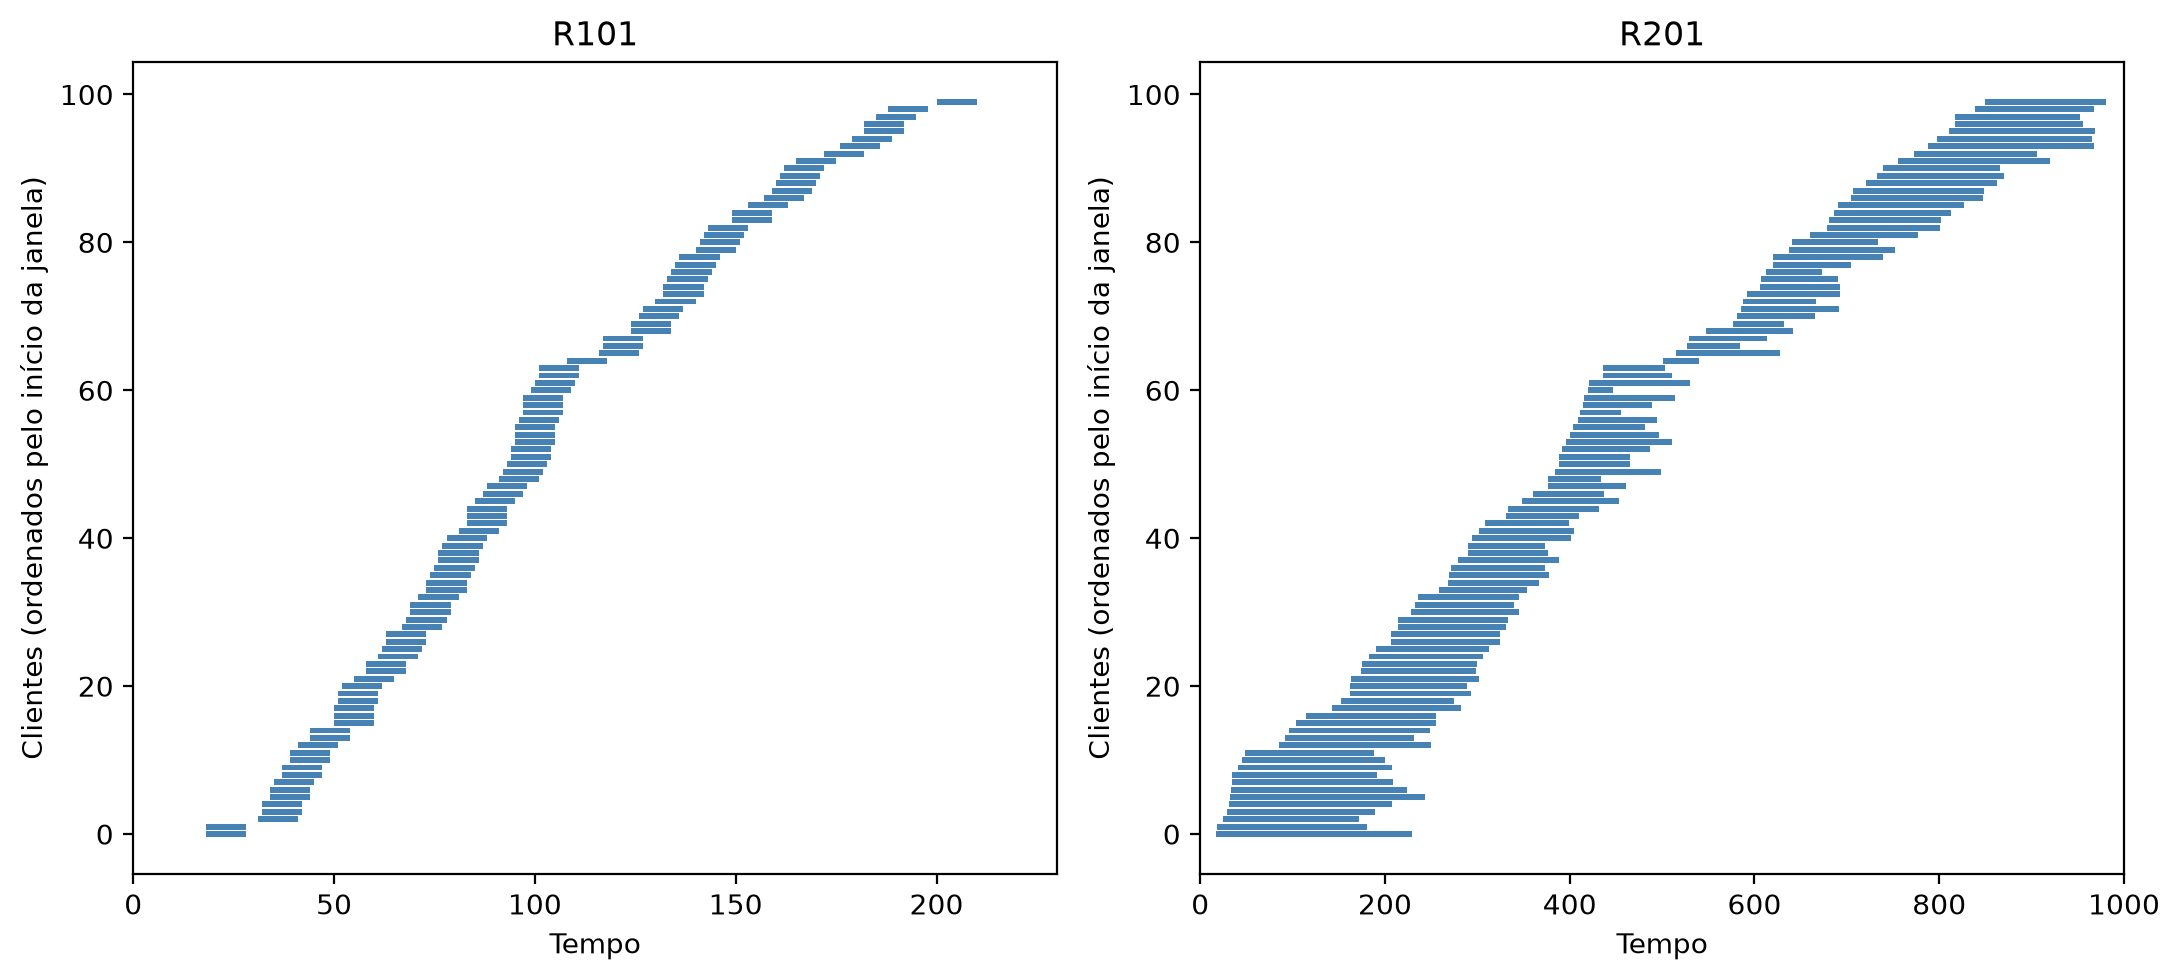

In [4]:
viz_eda.plot_window_comparison(instances, ["R101", "R201"], LANG)
plt.show()

### Insight

Em R101 as janelas formam faixas curtas sobre o horizonte de 0 a 230, com baixa sobreposição em cada instante, restringindo o atendimento a intervalos estreitos; em R201 as barras estendem-se sobre o horizonte de 0 a 1000 com sobreposição intensa. O contraste visual concorda com as larguras relativas mínimas da tabela anterior (0,043 em R1 e 0,116 em R2), embora represente apenas duas das 23 instâncias da classe R e descreva a estrutura temporal sem medir diretamente seu impacto sobre o tamanho da frota, tema da seção seguinte.

## 4. Demanda e capacidade

Para distinguir quando a frota decorre da capacidade dos veículos ou das janelas de tempo, compara-se o número de veículos da referência do SINTEF (SINTEF, 2008) com o limite inferior por capacidade, dado por ⌈demanda total / capacidade⌉ (Toth & Vigo, 2014). Quando ambos coincidem, a capacidade é a restrição determinante; quando a referência supera o limite, as janelas (isoladamente ou combinadas à capacidade) impõem veículos extras. A tabela consolida os valores por família, e o gráfico projeta cada instância frente à diagonal de igualdade (com leve deslocamento horizontal entre famílias para evitar sobreposição).

,Família,Nº de instâncias,Limite inferior por capacidade,Veículos SINTEF,Veículos SINTEF (mín.),Veículos SINTEF (máx.),Razão SINTEF / limite,Nº limitadas por capacidade
0,C1,9,10.0,10.00,10,10,1.00,9
1,C2,8,3.0,3.00,3,3,1.00,8
2,R1,12,8.0,11.92,9,19,1.49,0
3,R2,11,2.0,2.73,2,4,1.36,4
4,RC1,8,9.0,11.50,10,14,1.28,0
5,RC2,8,2.0,3.25,3,4,1.62,0


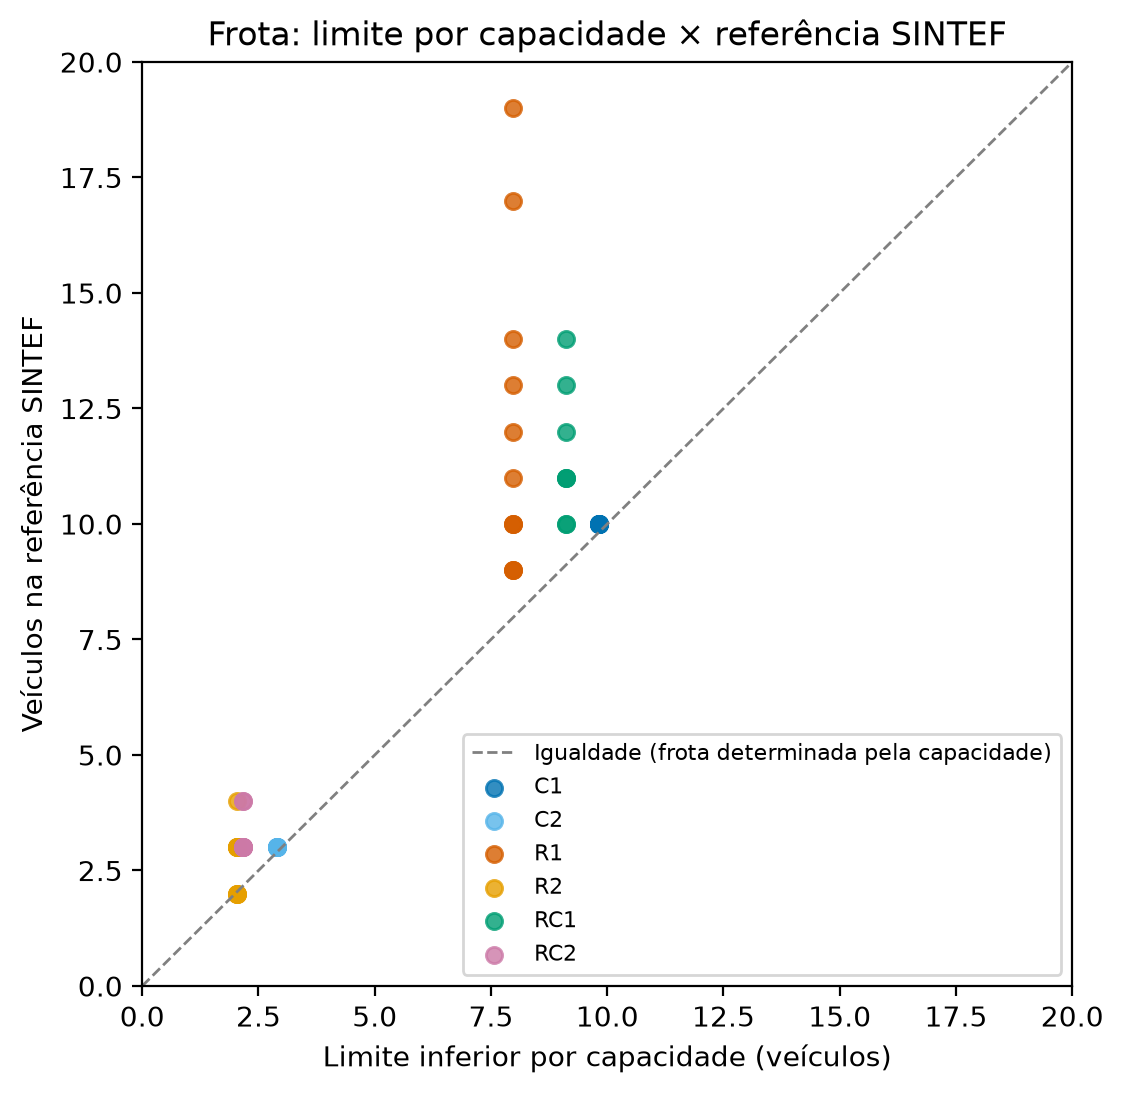

In [5]:
fleet = eda.fleet_bounds(instances, sintef)
display(eda.localize_columns(eda.fleet_summary(fleet), LANG))

viz_eda.plot_fleet_bounds(fleet, LANG)
plt.show()

### Insight

Nas famílias C a frota do SINTEF iguala o limite por capacidade em todas as instâncias (9 de 9 em C1 com 10 veículos e 8 de 8 em C2 com 3 veículos), confirmando que a capacidade rege a frota nesse grupo. Nas famílias R e RC a referência supera o limite inferior: R1 utiliza 11,92 veículos em média contra 8,0 (razão 1,49, variando de 9 a 19), RC1 utiliza 11,50 contra 9,0 (razão 1,28), R2 utiliza 2,73 contra 2,0 (razão 1,36, igualando em 4 de 11 casos) e RC2 utiliza 3,25 contra 2,0 (razão 1,62, sem igualar). Nessas famílias, as janelas de tempo ou sua interação com a capacidade exigem veículos adicionais. Como ressalva, o limite por capacidade ignora o roteamento (sendo frouxo por definição) e a referência do SINTEF corresponde à melhor solução conhecida, de modo que a diferença funciona como indicador da pressão das janelas. O passo seguinte mede a compatibilidade temporal direta entre pares de clientes.

## 5. Compatibilidade temporal

Para avaliar quantos pares ordenados de clientes (i, j), com i ≠ j, podem ser atendidos em sequência direta, testa-se a condição max(início_i, d₀ᵢ) + serviço_i + dᵢⱼ ≤ fim_j usando distâncias exatas e assumindo atendimento de i o mais cedo possível a partir do depósito (Toth & Vigo, 2014). A densidade de compatibilidade temporal, definida neste trabalho como a fração de pares que satisfazem essa desigualdade, mede a liberdade combinatória da instância: densidades menores restringem as combinações de rota possíveis. A tabela lista média, mínimo e máximo por família, e o gráfico mostra cada instância junto à mediana do grupo.

,Família,Densidade de compatibilidade,Densidade mínima,Densidade máxima
0,C1,0.640,0.435,0.942
1,C2,0.692,0.507,0.969
2,R1,0.693,0.306,0.991
3,R2,0.850,0.577,0.989
4,RC1,0.648,0.347,0.919
5,RC2,0.811,0.577,0.999


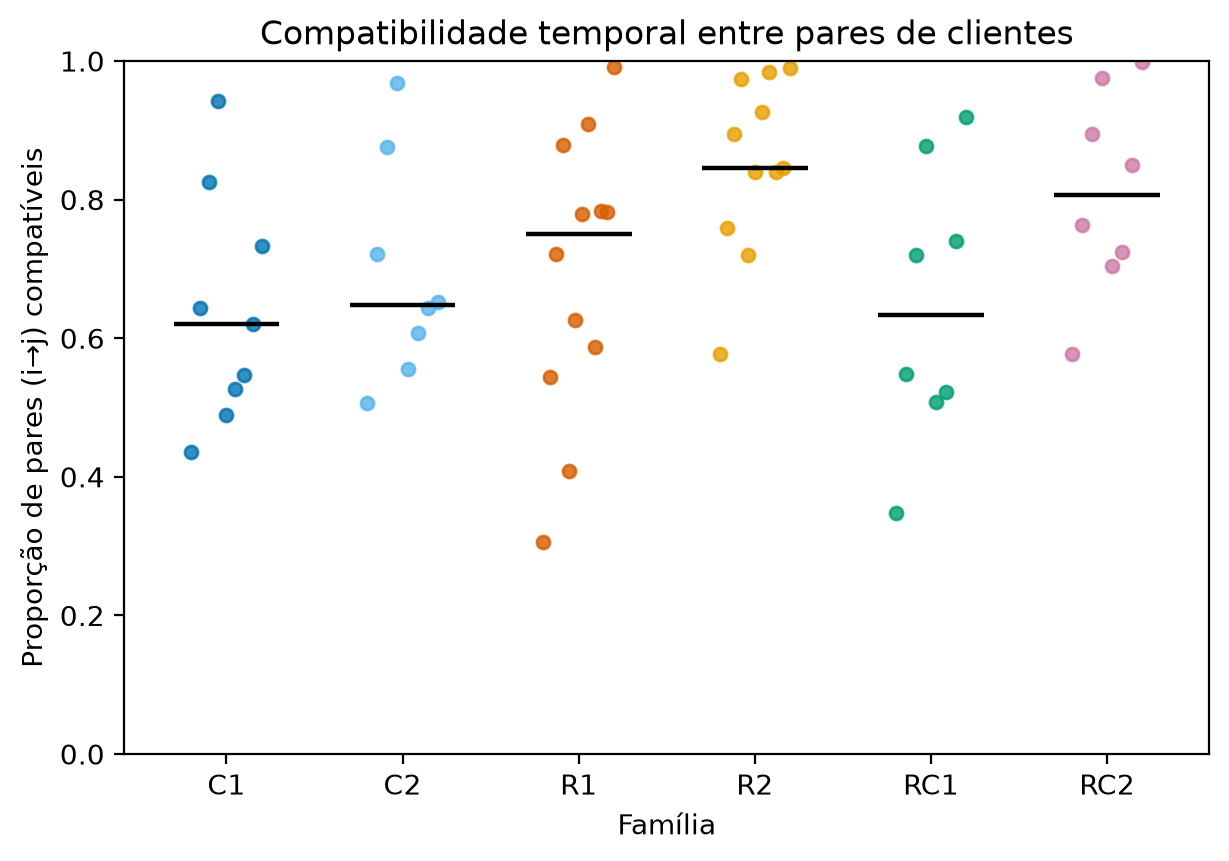

In [6]:
density = eda.compatibility_by_instance(instances)
display(eda.localize_columns(eda.compatibility_summary(density), LANG))

viz_eda.plot_compatibility(density, LANG)
plt.show()

### Insight

A densidade média de compatibilidade é mais alta nas séries 2 de R e RC (0,850 em R2 e 0,811 em RC2) do que nos demais grupos (0,640 em C1, 0,692 em C2, 0,693 em R1 e 0,648 em RC1). A dispersão interna permanece elevada, variando de 0,306 a 0,991 em R1 e de 0,347 a 0,919 em RC1, em magnitude comparável às diferenças entre famílias, mostrando que o rótulo familiar capta apenas parte da dificuldade estrutural. A associação dessa dispersão com a largura das janelas é plausível, embora não tenha sido testada aqui. Como limitações, a métrica avalia apenas pares consecutivos sem considerar capacidade, retorno ao depósito ou cadeias longas, e a diferença acentuada no tempo de serviço (90 em C contra 10 em R e RC) mistura efeitos de duração de serviço e de janela. Os indicadores estruturais são reunidos na síntese a seguir.

## 6. Síntese por família

A tabela consolida, para as seis famílias, a largura relativa média das janelas, a fração de clientes quase sem janela, o limite inferior médio por capacidade, a frota média do SINTEF, a razão entre os dois últimos e a densidade média de compatibilidade temporal.

In [7]:
synthesis = eda.synthesis_table(window, fleet, density)
display(eda.localize_columns(synthesis, LANG))

,Família,Largura / horizonte,Clientes quase sem janela,Limite inferior por capacidade,Veículos SINTEF,Razão SINTEF / limite,Densidade de compatibilidade
0,C1,0.260,0.104,10.0,10.000,1.000,0.640
1,C2,0.272,0.188,3.0,3.000,1.000,0.692
2,R1,0.378,0.027,8.0,11.917,1.490,0.693
3,R2,0.454,0.274,2.0,2.727,1.364,0.850
4,RC1,0.356,0.014,9.0,11.500,1.278,0.648
5,RC2,0.385,0.188,2.0,3.250,1.625,0.811


### Insight

Os indicadores separam claramente dois regimes. Nas famílias C, a razão entre frota de referência e limite por capacidade vale 1,000 tanto em C1 quanto em C2, com densidades de compatibilidade de 0,640 e 0,692. Em R e RC, essa razão sobe para valores entre 1,278 (RC1) e 1,625 (RC2), com densidades de 0,648 a 0,850. Nenhum indicador isolado ordena todos os grupos: R2 tem a maior densidade (0,850) e a maior fração de clientes quase livres (0,274), mas exibe razão de frota de 1,364, inferior à de R1 (1,490) e à de RC2 (1,625), indicando relação não monotônica entre largura de janela e frota excedente.

Como hipótese de comportamento para o solver, espera-se menor dificuldade de minimização de frota nas famílias C (em que o alvo coincide com o limite de capacidade) e maior exigência em R e RC devido à folga entre capacidade e referência. Esse padrão é compatível com os resultados da grade de desenvolvimento (`reports/protocolo-grade-dev.md`), nos quais a configuração selecionada igualou a frota do SINTEF nas 4 instâncias C de desenvolvimento, mas utilizou ao menos 1 veículo adicional em 9 das 10 instâncias R e RC (+1 em sete casos, +2 em R110 e +3 em RC106, igualando apenas em R201). Como limitação, a observação apoia-se em 14 instâncias com réplica única e reflete correlação descritiva entre entradas e saídas, sem vínculo causal comprovado. Na etapa seguinte executam-se as baselines e o solver, reportando separadamente Δ de veículos e gap de distância.

## 7. Próximos passos

A etapa seguinte traz o verificador independente, as heurísticas construtivas de baseline e os resultados do torneio de desenvolvimento nos notebooks 03 e 04, seguindo então para a avaliação final da configuração selecionada nas 42 instâncias inéditas no notebook 05, sempre com validação em precisão dupla. Em todas as comparações da Camada A, o Δ de veículos e o gap percentual de distância permanecem em colunas distintas, interpretando-se o gap apenas nos casos em que a frota iguala a referência do SINTEF. Por fim, as variações operacionais com janelas flexíveis, prioridades e perturbações são conduzidas em camada separada (notebooks 06 e 07), sem cálculo de gap contra o benchmark.

## Referências

- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research, 35*(2), 254–265.
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.